# Tarea 1

- Autor: Mauricio Montes
- Fecha: 15 jun 2025

## Imports

Tengo que trabajar con `seaborn`, así que tengo que importarlo. El módulo de las clases debería trabajar bien, sin tener que llamar aquí a `pandas`, así que solo voy a importar `seaborn` y `data_preprocessor.py`.

In [1]:
import seaborn as sns
import data_preprocessor as dp

## Cargando dataset

Utilizando `seaborn` para obtener el dataset *iris*, se carga el dataset en el objeto.

In [2]:
analizador = dp.DataAnalyzer()
analizador.dataframe = sns.load_dataset("iris")
analizador.dataframe.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Ahora, visualizamos qué tan limpio se encuentra el dataframe con el método `info()`.

In [3]:
analizador.dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


Además, verificamos si hay registros duplicados con el método `duplicates()`.

In [4]:
analizador.dataframe.duplicated().sum()

np.int64(1)

El dataset es bastante limpio, pues solo contiene un dato duplicado. Con el método `limpiar_datos()` se eliminarían esos datos duplicados.

In [5]:
analizador.limpiar_datos()

analizador.dataframe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  149 non-null    float64
 1   sepal_width   149 non-null    float64
 2   petal_length  149 non-null    float64
 3   petal_width   149 non-null    float64
 4   species       149 non-null    object 
dtypes: float64(4), object(1)
memory usage: 7.0+ KB


Ahora, realizamos un análisis estadístico exploratorio con el método `resumen()` del analizador.

In [6]:
analizador.resumen()

,sepal_length,sepal_width,petal_length,petal_width
max,7.900000,4.400000,6.900000,2.500000
min,4.300000,2.000000,1.000000,0.100000
media,5.843624,3.059732,3.748993,1.194631


## Visualización de datos

Se quiere realizar un gráfico de barras de la longitud promedio de los pétalos por especie. Para ello, primeramente, tenemos que ver cuántas especies están en el dataset.

In [9]:
analizador.dataframe['species'].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

En vista de que hay tres especies de flores distintas, vamos a agrupar el dataset por las especies y obtener la media de la longitud de los pétalos.

In [ ]:
df = analizador.dataframe.groupby('species')['petal_length'].mean().reset_index()
# groupby agrupa en base a la columna del parámetro
# groupby tiene que hacer algo con otra columna, en este caso 'petal_length'
# mean obtiene la media para la agrupación
# reset_index hace que lo que se guarde sea un DataFrame, no un Series
df

,species,petal_length
0,setosa,1.462000
1,versicolor,4.260000
2,virginica,5.561224


Ahora, vamos a graficar usando `matplotlib` un gráfico de barras.

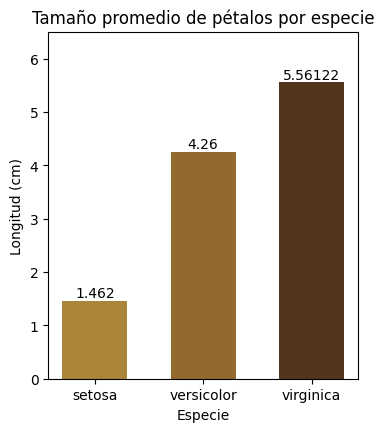

In [47]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
fig.set_size_inches(4, 4.5)                 # tamaño del lienzo
bars = ax.bar(
    df['species'], df['petal_length'],    # ejes del gráfico
    width=0.6,                            # ancho de columna
    color=['#aa853a', '#926a2d', "#52351b"]    # lista de colores
)
ax.bar_label(bars)     # necesario para que las barras tengan números
ax.set_ybound(0, 6.5)  # eje y de 0 a 6.5 unidades, para que se vean bien los números de las barras

ax.set_title("Tamaño promedio de pétalos por especie")     # título
ax.set_xlabel("Especie")                                   # nombre eje x
ax.set_ylabel("Longitud (cm)")                             # nombre eje y

plt.show()             # mostrar gráfico